In [1]:
# ============================================================
# ENSEMBLE METHODS AND REGULARIZATION
# ============================================================

print("ENSEMBLE METHODS")
print("Bagging, Boosting, XGBoost, LightGBM")
print("Bias-Variance Trade-off, Overfitting, Underfitting")
print("L1 and L2 Regularization")

ENSEMBLE METHODS
Bagging, Boosting, XGBoost, LightGBM
Bias-Variance Trade-off, Overfitting, Underfitting
L1 and L2 Regularization


In [2]:
!pip install xgboost lightgbm -q

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import warnings
warnings.filterwarnings("ignore")

In [4]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset Shape:", X.shape)
print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(data.target_names)

X.head()

Dataset Shape: (569, 30)

Features:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target Classes:
['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
print("Missing values:")
print(X.isnull().sum().sum())

print("\nClass distribution:")
print(y.value_counts())

print("\nDataset information:")
print(X.describe())

Missing values:
0

Class distribution:
target
1    357
0    212
Name: count, dtype: int64

Dataset information:
       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720   

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


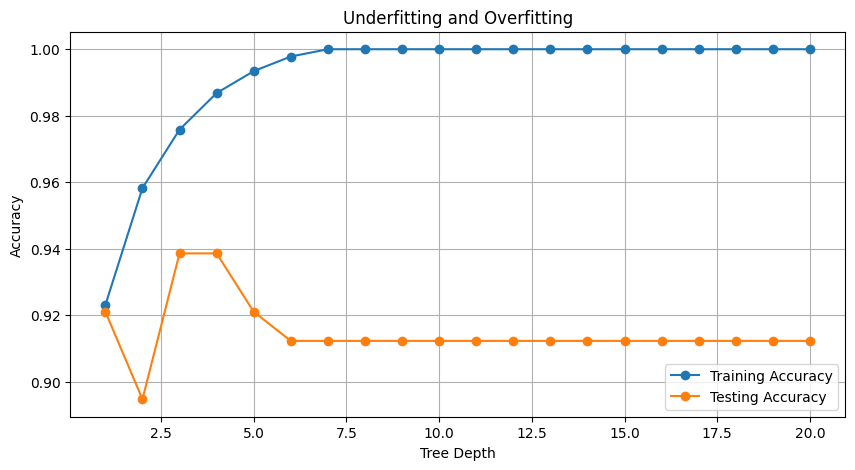

In [7]:
depths = range(1, 21)

train_scores = []
test_scores = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

plt.figure(figsize=(10, 5))

plt.plot(
    depths,
    train_scores,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    depths,
    test_scores,
    marker='o',
    label='Testing Accuracy'
)

plt.xlabel("Tree Depth")
plt.ylabel("Accuracy")
plt.title("Underfitting and Overfitting")
plt.legend()
plt.grid(True)

plt.show()

In [8]:
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),
    n_estimators=100,
    random_state=42
)

bagging_model.fit(X_train, y_train)

bagging_pred = bagging_model.predict(X_test)

bagging_accuracy = accuracy_score(
    y_test,
    bagging_pred
)

print("Bagging Accuracy:", bagging_accuracy)

Bagging Accuracy: 0.9385964912280702


In [9]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.956140350877193


In [10]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

xgb_accuracy = accuracy_score(
    y_test,
    xgb_pred
)

print("XGBoost Accuracy:", xgb_accuracy)

XGBoost Accuracy: 0.9473684210526315


In [11]:
lgb_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    num_leaves=15,
    random_state=42,
    verbosity=-1
)

lgb_model.fit(X_train, y_train)

lgb_pred = lgb_model.predict(X_test)

lgb_accuracy = accuracy_score(
    y_test,
    lgb_pred
)

print("LightGBM Accuracy:", lgb_accuracy)

LightGBM Accuracy: 0.956140350877193


In [12]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Bagging",
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],
    "Accuracy": [
        DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ).fit(X_train, y_train).score(X_test, y_test),

        bagging_accuracy,
        rf_accuracy,
        xgb_accuracy,
        lgb_accuracy
    ]
})

results

,Model,Accuracy
0,Decision Tree,0.921053
1,Bagging,0.938596
2,Random Forest,0.956140
3,XGBoost,0.947368
4,LightGBM,0.956140


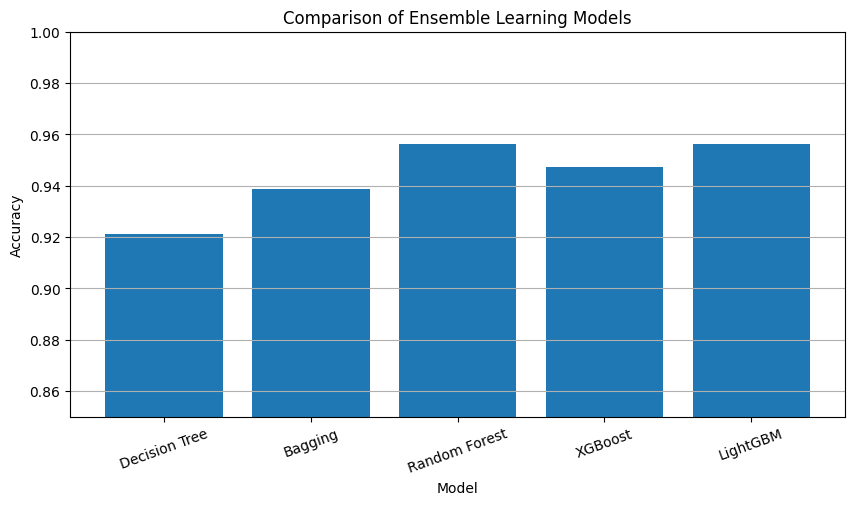

In [13]:
plt.figure(figsize=(10, 5))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Comparison of Ensemble Learning Models")

plt.xticks(rotation=20)

plt.ylim(0.85, 1.0)

plt.grid(axis='y')

plt.show()

In [14]:
models = {
    "Bagging": bagging_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "LightGBM": lgb_model
}

for name, model in models.items():

    predictions = model.predict(X_test)

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        predictions,
        target_names=data.target_names
    ))


Bagging
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114


Random Forest
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


XGBoost
              precision    recall  f1-score   support

   malignant       0.95      0.90      0.93        42
      benign       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.

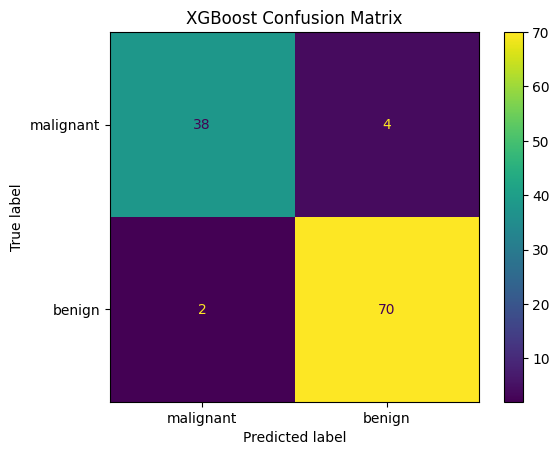

In [15]:
cm = confusion_matrix(y_test, xgb_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot()

plt.title("XGBoost Confusion Matrix")
plt.show()

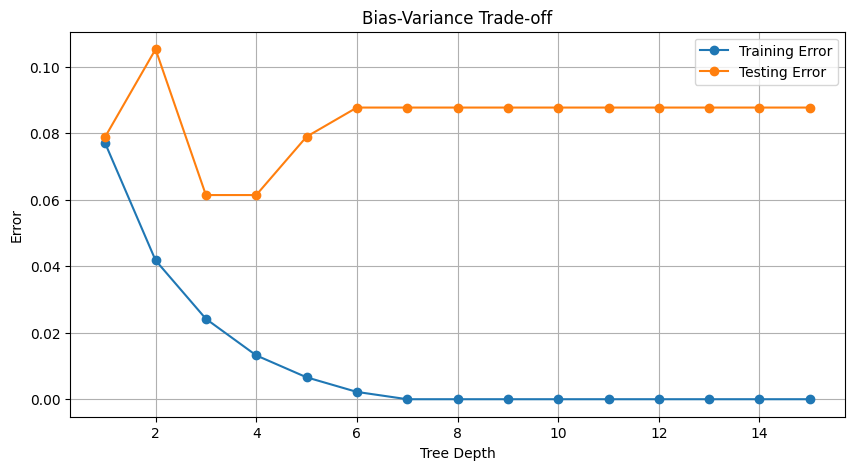

In [16]:
train_errors = []
test_errors = []

depths = range(1, 16)

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_errors.append(
        1 - model.score(X_train, y_train)
    )

    test_errors.append(
        1 - model.score(X_test, y_test)
    )

plt.figure(figsize=(10, 5))

plt.plot(
    depths,
    train_errors,
    marker='o',
    label="Training Error"
)

plt.plot(
    depths,
    test_errors,
    marker='o',
    label="Testing Error"
)

plt.xlabel("Tree Depth")
plt.ylabel("Error")
plt.title("Bias-Variance Trade-off")
plt.legend()
plt.grid(True)

plt.show()

In [17]:
l1_model = LogisticRegression(
    penalty='l1',
    solver='liblinear',
    C=1.0,
    max_iter=5000,
    random_state=42
)

l1_model.fit(X_train, y_train)

l1_pred = l1_model.predict(X_test)

l1_accuracy = accuracy_score(
    y_test,
    l1_pred
)

print("L1 Regularization Accuracy:", l1_accuracy)

L1 Regularization Accuracy: 0.9649122807017544


In [18]:
l2_model = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    C=1.0,
    max_iter=5000,
    random_state=42
)

l2_model.fit(X_train, y_train)

l2_pred = l2_model.predict(X_test)

l2_accuracy = accuracy_score(
    y_test,
    l2_pred
)

print("L2 Regularization Accuracy:", l2_accuracy)

L2 Regularization Accuracy: 0.956140350877193


  Regularization  Accuracy
0             L1  0.964912
1             L2  0.956140


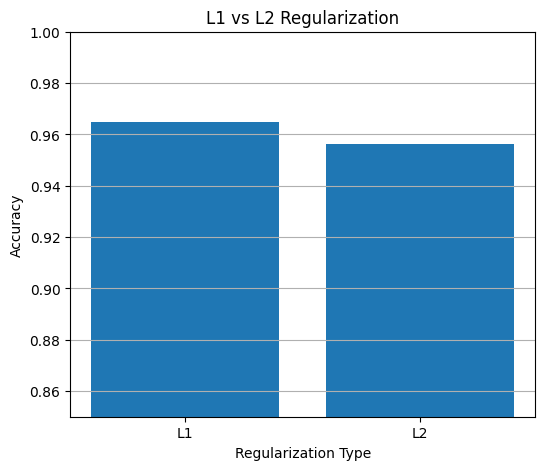

In [19]:
regularization_results = pd.DataFrame({
    "Regularization": [
        "L1",
        "L2"
    ],
    "Accuracy": [
        l1_accuracy,
        l2_accuracy
    ]
})

print(regularization_results)

plt.figure(figsize=(6, 5))

plt.bar(
    regularization_results["Regularization"],
    regularization_results["Accuracy"]
)

plt.xlabel("Regularization Type")
plt.ylabel("Accuracy")
plt.title("L1 vs L2 Regularization")

plt.ylim(0.85, 1.0)

plt.grid(axis='y')

plt.show()

                    Model  Accuracy
4  L1 Logistic Regression  0.964912
1           Random Forest  0.956140
5  L2 Logistic Regression  0.956140
3                LightGBM  0.956140
2                 XGBoost  0.947368
0                 Bagging  0.938596


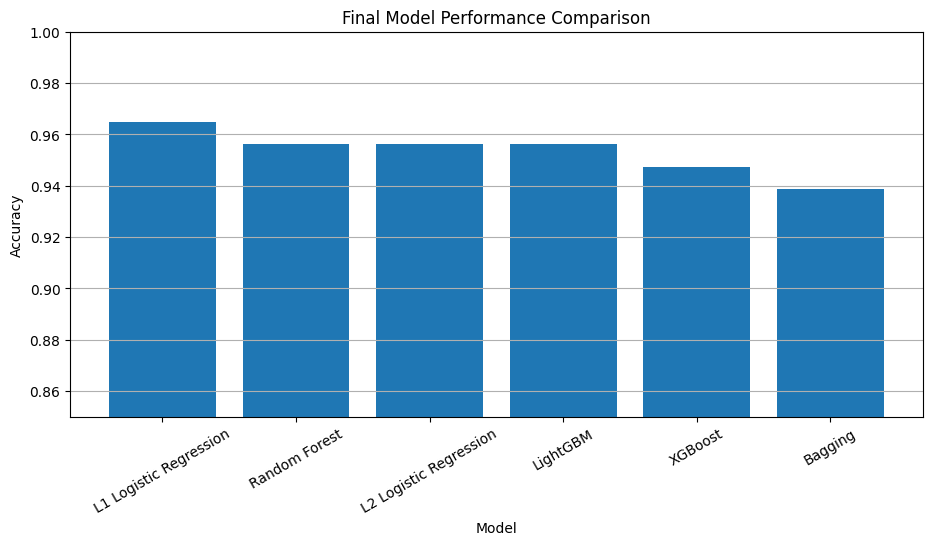

In [20]:
final_results = pd.DataFrame({
    "Model": [
        "Bagging",
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "L1 Logistic Regression",
        "L2 Logistic Regression"
    ],
    "Accuracy": [
        bagging_accuracy,
        rf_accuracy,
        xgb_accuracy,
        lgb_accuracy,
        l1_accuracy,
        l2_accuracy
    ]
})

final_results = final_results.sort_values(
    by="Accuracy",
    ascending=False
)

print(final_results)

plt.figure(figsize=(11, 5))

plt.bar(
    final_results["Model"],
    final_results["Accuracy"]
)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Final Model Performance Comparison")

plt.xticks(rotation=30)

plt.ylim(0.85, 1.0)

plt.grid(axis='y')

plt.show()

In [21]:
print("""
CONCLUSION

1. Bagging reduces variance by combining multiple models.
2. Random Forest is an effective bagging-based ensemble method.
3. Boosting builds models sequentially to improve weak learners.
4. XGBoost provides powerful and regularized gradient boosting.
5. LightGBM provides fast and efficient gradient boosting.
6. Very simple models can underfit because of high bias.
7. Very complex models can overfit because of high variance.
8. The bias-variance trade-off helps select appropriate model complexity.
9. L1 regularization can reduce unnecessary features.
10. L2 regularization controls large model coefficients.
11. Ensemble methods generally improve prediction performance
    and generalization compared with a single decision tree.
""")


CONCLUSION

1. Bagging reduces variance by combining multiple models.
2. Random Forest is an effective bagging-based ensemble method.
3. Boosting builds models sequentially to improve weak learners.
4. XGBoost provides powerful and regularized gradient boosting.
5. LightGBM provides fast and efficient gradient boosting.
6. Very simple models can underfit because of high bias.
7. Very complex models can overfit because of high variance.
8. The bias-variance trade-off helps select appropriate model complexity.
9. L1 regularization can reduce unnecessary features.
10. L2 regularization controls large model coefficients.
11. Ensemble methods generally improve prediction performance
    and generalization compared with a single decision tree.

